<a href="https://colab.research.google.com/github/Nasim-Amani/ramp-aware-solar/blob/main/E1b_Target_vs_Loss_3seeds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E1 / E1b: target × loss (univariate LSTM, 3 seeds)

## Aim
We forecast solar irradiance 10 to 60 seconds ahead with an LSTM, and study how well the forecasts capture **ramps**: sudden changes in irradiance caused by passing clouds. Standard models are trained and judged with MSE/RMSE, which rewards smooth forecasts. Such models can beat persistence on RMSE and still miss most ramps, which are the events that matter most for grid and battery control.

## What the data exploration showed
- Ramps occur almost only on broken-cloud days, are real (confirmed by an independent PV module) and are fast: most are completed within 10 s, and the sun often stays blocked for only about 20 s.
- On clear days persistence is almost perfect up to one minute; on broken-cloud days its error doubles within the first minute.
- From the past, the **chance** of a ramp is predictable, but its **exact timing and direction** hardly are. Ramps come in groups: once the sky becomes restless (many fast ups and downs from passing clouds), it usually stays restless for several minutes or longer, while calm periods also tend to stay calm. A model can therefore tell from the last few minutes whether a ramp is likely soon, but not exactly when the next cloud edge will arrive.

## Research questions
1. **Does a ramp-aware loss help?** Does adding a term on the size of the 10-s changes to the MSE loss improve ramp detection, and how much accuracy (RMSE skill) does it cost?
2. **Should the model predict the change instead of the value?** Does predicting the change from the current irradiance (and adding it to the current value) improve the forecasts, especially on clear days where persistence is almost perfect?
3. **Which inputs help?** Do time of day and measures of recent variability improve accuracy or ramp detection, compared with irradiance alone?
4. **What is the trade-off?** How do accuracy and ramp detection change as the weight λ of the ramp term increases?
5. **How robust are the results?** Do the conclusions hold for different lead times (10–60 s), for clear and broken-cloud days, and when each broken-cloud day is used as the test day?

## Experiments

| | Question | What changes |
|---|---|---|
| **E1** | 1 and 2 | target (value vs change) × loss (MSE vs ramp-aware), irradiance only |
| **E2** | 3 | + time of day |
| **E3** | 3 | + recent-variability features |
| **E4** | 4 | weight λ of the ramp term (0, 0.5, 1, 3, 10) |
| **E5** | 5 | each broken-cloud day used as the test day in turn |

**This notebook runs E1.**

## 1. Settings
All choices that stay fixed across the experiments are set here. Each setup is trained with 3 random seeds (E1b), so we can see how much the results change by chance alone. Seed 0 is the first E1 run; runs that are already finished are skipped.

Results are written to a CSV file after every run. If Colab disconnects, re-running the notebook skips the runs that are already done.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

STEP_S   = 10                          # resolution: 10-s averages
LOOKBACK = 60                          # input:  the last 60 steps (10 min)
HORIZON  = 6                           # output: the next 6 steps (10, 20, ..., 60 s)
LEADS    = STEP_S * np.arange(1, HORIZON + 1)
SEEDS    = [0, 1, 2]                   # E1b: 3 seeds per setup (seed 0 = the first E1 run)

HP = {"units": 64, "learning_rate": 1e-3, "batch_size": 128,
      "max_epochs": 100, "patience": 10}   # same for all setups (tuning comes later)

RESULTS_FILE = "E1_results.csv"        # one row per run

## 2. Data
1-s irradiance (`Solar_Rad_clean`), daylight records of the 11 complete days, averaged to 10 s (the model resolution chosen in the data exploration). Only irradiance is used as input in E1.

In [2]:
df = pd.read_csv("solar_data_final_columns.csv", index_col="DateTime", parse_dates=["DateTime"])

data = (df.loc[df["full_day"] & df["daylight"], ["Solar_Rad_clean"]]
          .rename(columns={"Solar_Rad_clean": "G"})        # G = irradiance (W/m²)
          .resample(f"{STEP_S}s").mean()
          .dropna())     # removes only the night steps (checked: no NaN and no gaps inside daylight)

print(f"10-s daylight steps: {len(data):,}")

10-s daylight steps: 46,794


## 3. Split and day types
- **Split by whole days, in time order:** train 16–23 Feb, validation 24 Feb, test 25 Feb (broken clouds) and 26 Feb (clear).
- **Day types** come from the Variability Index in the data exploration notebook.

In [3]:
days = sorted(set(data.index.date))
TRAIN_DAYS, VAL_DAYS, TEST_DAYS = days[:8], days[8:9], days[9:]

# Day types from the Variability Index (data exploration notebook)
DAY_TYPE = {pd.Timestamp(d).date(): typ for d, typ in {
    "2013-02-16": "clear",         "2013-02-17": "few clouds",    "2013-02-18": "broken clouds",
    "2013-02-19": "clear",         "2013-02-20": "broken clouds", "2013-02-21": "clear",
    "2013-02-22": "clear",         "2013-02-23": "few clouds",    "2013-02-24": "broken clouds",
    "2013-02-25": "broken clouds", "2013-02-26": "clear"}.items()}

for name, dl in [("train", TRAIN_DAYS), ("validation", VAL_DAYS), ("test", TEST_DAYS)]:
    print(f"{name:11s}", ", ".join(f"{d:%d %b} ({DAY_TYPE[d]})" for d in dl))

train       16 Feb (clear), 17 Feb (few clouds), 18 Feb (broken clouds), 19 Feb (clear), 20 Feb (broken clouds), 21 Feb (clear), 22 Feb (clear), 23 Feb (few clouds)
validation  24 Feb (broken clouds)
test        25 Feb (broken clouds), 26 Feb (clear)


## 4. Ramp threshold

**Goal:** decide how large a 10-s change must be to count as a ramp, based on the data.

1. **10-s changes.** For each day, we subtract each 10-s value from the next one, e.g. 790 → 650 W/m² gives a change of −140 W/m². Changes are only computed between values that are exactly 10 s apart.
2. **Which days.** We use only the broken-cloud **training** days (18 and 20 Feb): clear days have almost only tiny changes, and the test days must not influence a threshold that is later used to score the models. Drops and rises are treated the same, so we use the size of each change (−140 and +140 both count as 140).
3. **Threshold.** A ramp is a change among the largest 5 % of these changes, i.e. larger than their 95th percentile. Rounded to 10 W/m², this gives **80 W/m² per 10 s**.

All ramp results use this threshold. As a sensitivity check, we also report results at 60 W/m².

In [4]:
def changes_of_day(day):
    # 10-s changes of irradiance within one day, only between real neighbouring steps
    g = data.loc[data.index.date == day, "G"]
    ok = g.index.to_series().diff() == pd.Timedelta(seconds=STEP_S)
    return g.diff()[ok]

broken_train = [d for d in TRAIN_DAYS if DAY_TYPE[d] == "broken clouds"]
train_changes = pd.concat([changes_of_day(d) for d in broken_train]).abs()

THRESHOLD       = int(round(np.percentile(train_changes, 95), -1))   # main threshold (W/m² per 10 s)
THRESHOLD_CHECK = 60                                                  # sensitivity check
print(f"Ramp threshold: {THRESHOLD} W/m² per 10 s   (check: {THRESHOLD_CHECK})")

Ramp threshold: 80 W/m² per 10 s   (check: 60)


## 5. Training examples (windows)

Each training example is a **window** of 66 consecutive 10-s values: the first 60 (10 min) are the input, and the next 6 (10, 20, …, 60 s) are the targets. We slide this window forward one step at a time to create many examples.

- **One day per window.** Because the nights were removed, the last value of one day is directly followed by the first value of the next morning in the data, although 12 hours lie between them. We therefore cut windows inside each day separately, so no example mixes the evening of one day with the morning of the next.
- **No gaps.** A window is used only if its 66 values are exactly 10 s apart; windows with a missing step are skipped.
- **Current value.** For each example we also keep the current irradiance ("now", the last input value), which is needed for persistence and for the change target.

In [5]:
def make_windows(days_list, inputs):
    # Returns X (examples, LOOKBACK, features), Y (examples, HORIZON) in W/m²,
    # now (examples, 1) = irradiance at the forecast time, and the forecast times
    X, Y, now, t = [], [], [], []
    span = pd.Timedelta(seconds=STEP_S * (LOOKBACK + HORIZON - 1))
    for day in days_list:
        d = data[data.index.date == day]
        n = len(d) - LOOKBACK - HORIZON + 1
        if n <= 0:
            continue
        start = np.arange(n)
        ok = (d.index[start + LOOKBACK + HORIZON - 1] - d.index[start]) == span   # no missing step inside
        x = np.lib.stride_tricks.sliding_window_view(d[inputs].to_numpy(), LOOKBACK, axis=0)[:n]
        y = np.lib.stride_tricks.sliding_window_view(d["G"].to_numpy(), HORIZON)[LOOKBACK:LOOKBACK + n]
        X.append(x.transpose(0, 2, 1)[ok])
        Y.append(y[ok])
        now.append(d["G"].to_numpy()[start + LOOKBACK - 1][ok])
        t.append(d.index[start + LOOKBACK - 1][ok])
    return (np.concatenate(X), np.concatenate(Y),
            np.concatenate(now)[:, None], pd.DatetimeIndex(np.concatenate(t)))


_windows = {}                          # windows are built once per input set and reused
def get_windows(inputs):
    key = tuple(inputs)
    if key not in _windows:
        _windows[key] = {name: make_windows(dl, inputs)
                         for name, dl in [("train", TRAIN_DAYS), ("val", VAL_DAYS), ("test", TEST_DAYS)]}
    return _windows[key]

w = get_windows(["G"])
print({name: len(v[0]) for name, v in w.items()}, " input shape:", w["train"][0].shape)

{'train': 33410, 'val': 4213, 'test': 8456}  input shape: (33410, 60, 1)


## 6. Loss function

We use one loss function for all four setups:

$$L = \underbrace{\frac{1}{6}\sum_{k=1}^{6}\big(\hat G_{t+k} - G_{t+k}\big)^2}_{\text{error in the values}} \;+\; \lambda \cdot \underbrace{\frac{1}{6}\sum_{k=1}^{6}\big(|\Delta \hat G_{t+k}| - |\Delta G_{t+k}|\big)^2}_{\text{error in the size of each 10-s change}}$$

(averaged over all examples), where $\Delta G_{t+k} = G_{t+k} - G_{t+k-1}$ is the change from one 10-s step to the next along the forecast path, starting from the current value $G_t$.

- The **first term** is the usual MSE.
- The **second term** compares the *size* of each predicted change with the real one, so a forecast that is too smooth is penalised, even if the timing of a ramp is slightly wrong. It is the gradient difference loss of Mathieu et al. (2016), originally proposed to reduce blurry predictions in video forecasting, applied here along the time axis of the forecast path.
- **λ = 0** gives plain MSE; **λ = 1** is our ramp-aware loss.

The same loss is used for both targets (value and change), since the 10-s changes along the path are the same in both cases. To score the first step (from "now" to +10 s), the loss needs the current value, so we pass it as an extra first column of the targets.

In [6]:
def ramp_aware_loss(lam):
    def loss(y_true, y_pred):
        start, y = y_true[:, :1], y_true[:, 1:]          # first column = start of the path ("now")
        path_true = tf.concat([start, y], axis=1)
        path_pred = tf.concat([start, y_pred], axis=1)
        step_true = path_true[:, 1:] - path_true[:, :-1]  # real 10-s changes
        step_pred = path_pred[:, 1:] - path_pred[:, :-1]  # predicted 10-s changes
        mse_values = tf.reduce_mean(tf.square(y - y_pred))
        mse_size   = tf.reduce_mean(tf.square(tf.abs(step_pred) - tf.abs(step_true)))
        return mse_values + lam * mse_size
    return loss

## 7. Evaluation
- **Skill** against persistence: $1 - \text{RMSE}_{model} / \text{RMSE}_{persistence}$ (in %), for each lead time and for each day type.
- **Ramps** on the broken-cloud test day: each forecast is a path now → +10 s → … → +60 s. A ramp is a step in the path larger than the threshold. A predicted ramp counts as correct if the measured path has a ramp in the same direction within ±1 step (±10 s). We report precision, recall and F1.

In [7]:
TOL = 1                                          # timing tolerance: ±1 step (±10 s)

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

def widen(mask, tol):
    # mark each event and its ±tol neighbouring steps along the path
    out = mask.copy()
    for s in range(1, tol + 1):
        out[:, s:]  |= mask[:, :-s]
        out[:, :-s] |= mask[:, s:]
    return out

def ramp_scores(obs, pred, thr):
    # precision, recall and F1 for up- and down-ramps together
    hit_obs = hit_pred = n_obs = n_pred = 0
    for sign in (+1, -1):
        o, p = sign * obs > thr, sign * pred > thr
        hit_obs  += (o & widen(p, TOL)).sum()     # measured ramps that were predicted
        hit_pred += (p & widen(o, TOL)).sum()     # predicted ramps that really happened
        n_obs, n_pred = n_obs + o.sum(), n_pred + p.sum()
    recall    = hit_obs / n_obs if n_obs else np.nan
    precision = hit_pred / n_pred if n_pred else np.nan
    f1 = 2 * precision * recall / (precision + recall) if n_pred and (precision + recall) else 0.0
    return {"precision": precision, "recall": recall, "F1": f1}

def evaluate(P, Y, now, t):
    # all scores of one set of test forecasts P (W/m²)
    pers  = np.repeat(now, HORIZON, axis=1)                    # persistence forecast
    types = np.array([DAY_TYPE[d] for d in t.date])
    res = {"skill all": 100 * (1 - rmse(Y, P) / rmse(Y, pers))}
    for typ in ["broken clouds", "clear"]:
        m = types == typ
        res[f"skill {typ}"] = 100 * (1 - rmse(Y[m], P[m]) / rmse(Y[m], pers[m]))
        res[f"RMSE {typ}"]  = rmse(Y[m], P[m])
    for k, lead in enumerate(LEADS):
        res[f"skill {lead}s"] = 100 * (1 - rmse(Y[:, k], P[:, k]) / rmse(Y[:, k], pers[:, k]))
    m = types == "broken clouds"                               # ramps: broken-cloud test day
    obs  = np.diff(np.hstack([now, Y]), axis=1)[m]
    pred = np.diff(np.hstack([now, P]), axis=1)[m]
    for thr in [THRESHOLD, THRESHOLD_CHECK]:
        res.update({f"{k} @{thr}": v for k, v in ramp_scores(obs, pred, thr).items()})
    return res

# Reference: persistence on the test days
_, Y_te, now_te, t_te = get_windows(["G"])["test"]
ref = evaluate(np.repeat(now_te, HORIZON, axis=1), Y_te, now_te, t_te)
print(f"Persistence RMSE: broken-cloud day {ref['RMSE broken clouds']:.1f} W/m², "
      f"clear day {ref['RMSE clear']:.1f} W/m²   (persistence never predicts a ramp)")

Persistence RMSE: broken-cloud day 89.8 W/m², clear day 2.2 W/m²   (persistence never predicts a ramp)


## 8. One experiment = one function call
`run_experiment(target, lam, inputs, seed)` builds the training data, trains the LSTM and returns all scores.

- **target = "level":** the network predicts the irradiance values (scaled 0–1).
- **target = "change":** the network predicts the change from the current value, and the forecast is *now + change*. Its output layer starts at zero, so the untrained model equals persistence.

Both targets use the same scale (the range of irradiance on the training days), so their losses are comparable. Inputs are min-max scaled with the training data only.

In [8]:
def run_experiment(target, lam, inputs, seed):
    (X_tr, Y_tr, now_tr, _), (X_va, Y_va, now_va, _), (X_te, Y_te, now_te, t_te) = get_windows(inputs).values()

    # ---- Scaling (training data only) ----
    x_min = X_tr.reshape(-1, len(inputs)).min(axis=0)
    x_max = X_tr.reshape(-1, len(inputs)).max(axis=0)
    scale_x = lambda X: (X - x_min) / (x_max - x_min)
    y_min, y_scale = Y_tr.min(), Y_tr.max() - Y_tr.min()

    def to_target(Y, now):
        # what the network learns; the first column is the start of the path (for the loss)
        if target == "level":
            return np.hstack([(now - y_min) / y_scale, (Y - y_min) / y_scale])
        return np.hstack([np.zeros_like(now), (Y - now) / y_scale])

    def to_wm2(P, now):
        # network output back to irradiance (W/m²)
        P = P * y_scale + (y_min if target == "level" else now)
        return np.clip(P, 0, None)

    # ---- Model ----
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK, len(inputs))),
        tf.keras.layers.LSTM(HP["units"]),
        tf.keras.layers.Dense(HORIZON, kernel_initializer="zeros" if target == "change" else "glorot_uniform"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(HP["learning_rate"]), loss=ramp_aware_loss(lam))

    # ---- Training with early stopping on the validation day ----
    stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["patience"], restore_best_weights=True)
    hist = model.fit(scale_x(X_tr), to_target(Y_tr, now_tr),
                     validation_data=(scale_x(X_va), to_target(Y_va, now_va)),
                     epochs=HP["max_epochs"], batch_size=HP["batch_size"], callbacks=[stop],
                     verbose=2)                                    # one line per epoch

    # ---- Training curve of this run ----
    best = int(np.argmin(hist.history["val_loss"])) + 1
    plt.figure(figsize=(5, 3))
    plt.plot(hist.history["loss"], label="train")
    plt.plot(hist.history["val_loss"], label="validation")
    plt.axvline(best - 1, color="gray", ls="--", lw=0.8, label=f"best epoch ({best})")
    plt.title(f"{target}, λ = {lam}, seed {seed}"); plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.tight_layout(); plt.show()

    # ---- Test forecasts and scores ----
    P = to_wm2(model.predict(scale_x(X_te), verbose=0), now_te)
    np.save(f"pred_{target}_lam{lam}_seed{seed}.npy", P)          # keep the test forecasts (W/m²) for the result tables
    res = {"target": target, "lambda": lam, "inputs": "+".join(inputs), "seed": seed,
           "best epoch": best}
    res.update(evaluate(P, Y_te, now_te, t_te))
    return res

## 9. Run E1: target × loss
Four setups with 3 seeds each (12 runs), input = irradiance only. The 4 runs with seed 0 (first E1 run) are skipped if their results are still in the CSV file, so only 8 new runs are trained. Training runs for at most 100 epochs; early stopping ends it when the validation loss has not improved for 10 epochs and restores the best epoch. Each finished run (scores and test forecasts) is saved immediately.

The model is small, so a CPU runtime is enough; each run takes roughly 10 minutes.

Epoch 1/100
262/262 - 23s - 89ms/step - loss: 0.0119 - val_loss: 0.0038
Epoch 2/100
262/262 - 19s - 74ms/step - loss: 0.0020 - val_loss: 0.0037
Epoch 3/100
262/262 - 21s - 82ms/step - loss: 0.0019 - val_loss: 0.0037
Epoch 4/100
262/262 - 19s - 74ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 5/100
262/262 - 21s - 79ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 6/100
262/262 - 20s - 76ms/step - loss: 0.0017 - val_loss: 0.0034
Epoch 7/100
262/262 - 19s - 73ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 8/100
262/262 - 22s - 82ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 9/100
262/262 - 19s - 74ms/step - loss: 0.0015 - val_loss: 0.0032
Epoch 10/100
262/262 - 22s - 86ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 11/100
262/262 - 19s - 74ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 12/100
262/262 - 21s - 81ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 13/100
262/262 - 20s - 75ms/step - loss: 0.0014 - val_loss: 0.0030
Epoch 14/100
262/262 - 21s - 82ms/step - loss: 0.0014 - val_

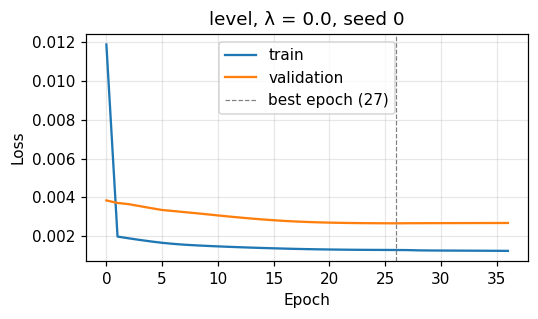

level  λ=0.0  seed=0  epochs= 27  skill=  5.7 %  F1@80=0.003
Epoch 1/100
262/262 - 23s - 89ms/step - loss: 0.0130 - val_loss: 0.0039
Epoch 2/100
262/262 - 19s - 74ms/step - loss: 0.0020 - val_loss: 0.0039
Epoch 3/100
262/262 - 22s - 83ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 4/100
262/262 - 19s - 74ms/step - loss: 0.0018 - val_loss: 0.0039
Epoch 5/100
262/262 - 21s - 81ms/step - loss: 0.0017 - val_loss: 0.0037
Epoch 6/100
262/262 - 19s - 74ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 7/100
262/262 - 20s - 77ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 8/100
262/262 - 21s - 78ms/step - loss: 0.0016 - val_loss: 0.0031
Epoch 9/100
262/262 - 20s - 76ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 10/100
262/262 - 22s - 82ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 11/100
262/262 - 19s - 74ms/step - loss: 0.0015 - val_loss: 0.0029
Epoch 12/100
262/262 - 22s - 83ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 13/100
262/262 - 20s - 75ms/step - loss: 0.0014 - val_loss: 0.0028

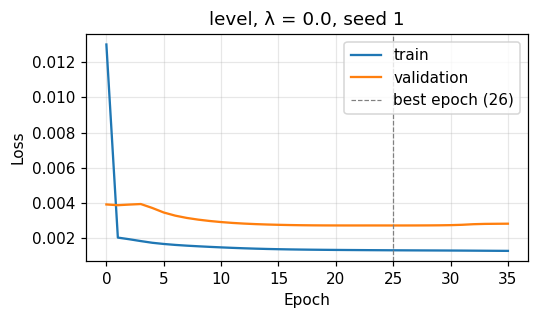

level  λ=0.0  seed=1  epochs= 26  skill=  4.9 %  F1@80=0.008
Epoch 1/100
262/262 - 22s - 83ms/step - loss: 0.0108 - val_loss: 0.0038
Epoch 2/100
262/262 - 21s - 82ms/step - loss: 0.0020 - val_loss: 0.0037
Epoch 3/100
262/262 - 19s - 74ms/step - loss: 0.0019 - val_loss: 0.0036
Epoch 4/100
262/262 - 23s - 87ms/step - loss: 0.0018 - val_loss: 0.0035
Epoch 5/100
262/262 - 19s - 74ms/step - loss: 0.0018 - val_loss: 0.0034
Epoch 6/100
262/262 - 22s - 82ms/step - loss: 0.0017 - val_loss: 0.0033
Epoch 7/100
262/262 - 41s - 155ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 8/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 9/100
262/262 - 20s - 75ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 10/100
262/262 - 21s - 79ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 11/100
262/262 - 19s - 73ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 12/100
262/262 - 22s - 86ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 13/100
262/262 - 19s - 74ms/step - loss: 0.0014 - val_loss: 0.002

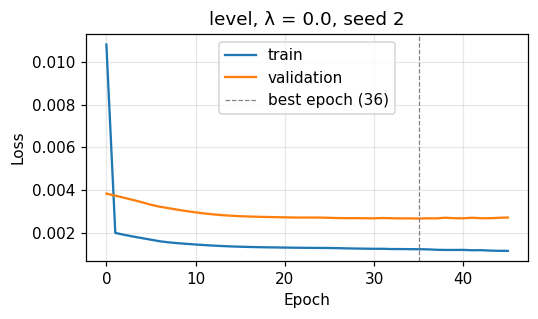

level  λ=0.0  seed=2  epochs= 36  skill=  1.3 %  F1@80=0.010
Epoch 1/100
262/262 - 22s - 84ms/step - loss: 0.0142 - val_loss: 0.0047
Epoch 2/100
262/262 - 42s - 159ms/step - loss: 0.0025 - val_loss: 0.0046
Epoch 3/100
262/262 - 20s - 75ms/step - loss: 0.0023 - val_loss: 0.0045
Epoch 4/100
262/262 - 20s - 78ms/step - loss: 0.0022 - val_loss: 0.0044
Epoch 5/100
262/262 - 21s - 79ms/step - loss: 0.0022 - val_loss: 0.0043
Epoch 6/100
262/262 - 19s - 74ms/step - loss: 0.0021 - val_loss: 0.0042
Epoch 7/100
262/262 - 22s - 82ms/step - loss: 0.0020 - val_loss: 0.0041
Epoch 8/100
262/262 - 19s - 74ms/step - loss: 0.0020 - val_loss: 0.0040
Epoch 9/100
262/262 - 21s - 82ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 10/100
262/262 - 41s - 156ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 11/100
262/262 - 19s - 73ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 12/100
262/262 - 21s - 82ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 13/100
262/262 - 41s - 156ms/step - loss: 0.0018 - val_loss: 0.0

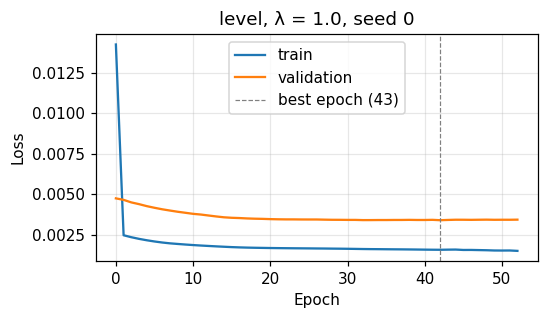

level  λ=1.0  seed=0  epochs= 43  skill=  1.2 %  F1@80=0.154
Epoch 1/100
262/262 - 23s - 89ms/step - loss: 0.0150 - val_loss: 0.0049
Epoch 2/100
262/262 - 41s - 155ms/step - loss: 0.0025 - val_loss: 0.0048
Epoch 3/100
262/262 - 19s - 74ms/step - loss: 0.0024 - val_loss: 0.0048
Epoch 4/100
262/262 - 21s - 82ms/step - loss: 0.0023 - val_loss: 0.0048
Epoch 5/100
262/262 - 19s - 74ms/step - loss: 0.0022 - val_loss: 0.0046
Epoch 6/100
262/262 - 22s - 85ms/step - loss: 0.0021 - val_loss: 0.0044
Epoch 7/100
262/262 - 19s - 74ms/step - loss: 0.0020 - val_loss: 0.0042
Epoch 8/100
262/262 - 21s - 82ms/step - loss: 0.0020 - val_loss: 0.0040
Epoch 9/100
262/262 - 19s - 74ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 10/100
262/262 - 21s - 80ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 11/100
262/262 - 20s - 76ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 12/100
262/262 - 19s - 74ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 13/100
262/262 - 22s - 82ms/step - loss: 0.0018 - val_loss: 0.003

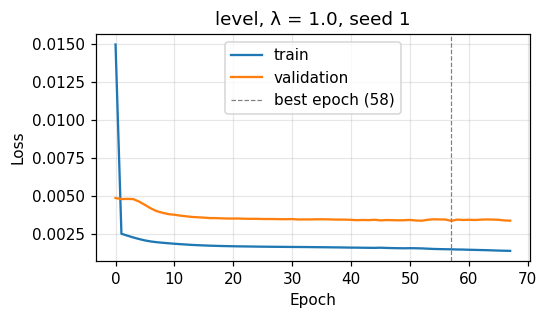

level  λ=1.0  seed=1  epochs= 58  skill= -4.5 %  F1@80=0.191
Epoch 1/100
262/262 - 24s - 91ms/step - loss: 0.0127 - val_loss: 0.0048
Epoch 2/100
262/262 - 20s - 75ms/step - loss: 0.0025 - val_loss: 0.0047
Epoch 3/100
262/262 - 22s - 86ms/step - loss: 0.0024 - val_loss: 0.0045
Epoch 4/100
262/262 - 19s - 74ms/step - loss: 0.0023 - val_loss: 0.0044
Epoch 5/100
262/262 - 22s - 82ms/step - loss: 0.0022 - val_loss: 0.0043
Epoch 6/100
262/262 - 19s - 74ms/step - loss: 0.0021 - val_loss: 0.0041
Epoch 7/100
262/262 - 22s - 83ms/step - loss: 0.0020 - val_loss: 0.0040
Epoch 8/100
262/262 - 20s - 75ms/step - loss: 0.0020 - val_loss: 0.0039
Epoch 9/100
262/262 - 21s - 82ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 10/100
262/262 - 19s - 74ms/step - loss: 0.0019 - val_loss: 0.0037
Epoch 11/100
262/262 - 21s - 82ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 12/100
262/262 - 20s - 75ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 13/100
262/262 - 20s - 76ms/step - loss: 0.0018 - val_loss: 0.0036

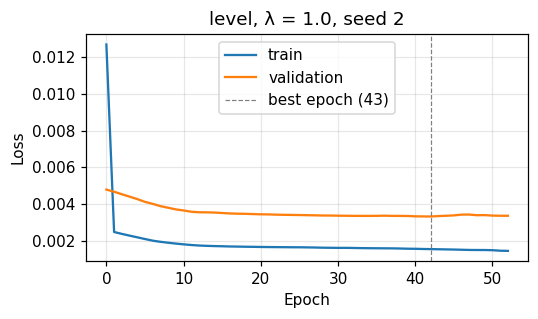

level  λ=1.0  seed=2  epochs= 43  skill= -0.3 %  F1@80=0.140
Epoch 1/100
262/262 - 21s - 82ms/step - loss: 0.0014 - val_loss: 0.0030
Epoch 2/100
262/262 - 21s - 82ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 3/100
262/262 - 41s - 156ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 4/100
262/262 - 19s - 74ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 5/100
262/262 - 21s - 82ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 6/100
262/262 - 20s - 74ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 7/100
262/262 - 21s - 80ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 8/100
262/262 - 20s - 76ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 9/100
262/262 - 22s - 82ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 10/100
262/262 - 20s - 77ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 11/100
262/262 - 21s - 82ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 12/100
262/262 - 20s - 78ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 13/100
262/262 - 20s - 78ms/step - loss: 0.0012 - val_loss: 0.002

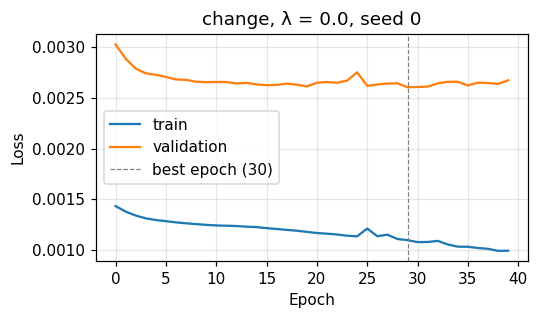

change λ=0.0  seed=0  epochs= 30  skill= -1.3 %  F1@80=0.019
Epoch 1/100
262/262 - 23s - 86ms/step - loss: 0.0014 - val_loss: 0.0031
Epoch 2/100
262/262 - 20s - 77ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 3/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 4/100
262/262 - 21s - 81ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 5/100
262/262 - 19s - 74ms/step - loss: 0.0013 - val_loss: 0.0029
Epoch 6/100
262/262 - 21s - 82ms/step - loss: 0.0013 - val_loss: 0.0030
Epoch 7/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0029
Epoch 8/100
262/262 - 22s - 86ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 9/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 10/100
262/262 - 22s - 85ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 11/100
262/262 - 19s - 74ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 12/100
262/262 - 21s - 82ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 13/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0028

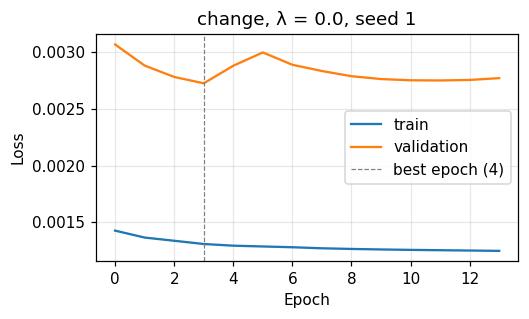

change λ=0.0  seed=1  epochs=  4  skill=  5.8 %  F1@80=0.000
Epoch 1/100
262/262 - 21s - 81ms/step - loss: 0.0014 - val_loss: 0.0030
Epoch 2/100
262/262 - 22s - 84ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 3/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 4/100
262/262 - 22s - 83ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 5/100
262/262 - 19s - 74ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 6/100
262/262 - 23s - 87ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 7/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 8/100
262/262 - 21s - 82ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 9/100
262/262 - 19s - 74ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 10/100
262/262 - 23s - 87ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 11/100
262/262 - 19s - 74ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 12/100
262/262 - 21s - 81ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 13/100
262/262 - 19s - 74ms/step - loss: 0.0012 - val_loss: 0.0027

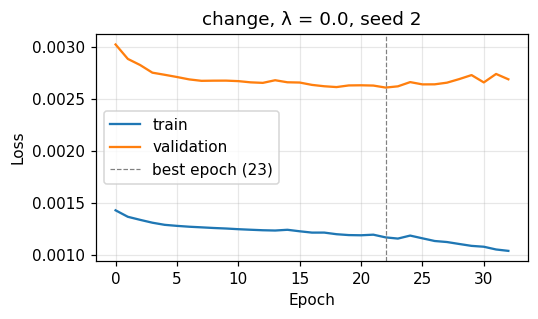

change λ=0.0  seed=2  epochs= 23  skill= -4.4 %  F1@80=0.014
Epoch 1/100
262/262 - 23s - 86ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 2/100
262/262 - 21s - 80ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 3/100
262/262 - 20s - 76ms/step - loss: 0.0017 - val_loss: 0.0036
Epoch 4/100
262/262 - 21s - 78ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 5/100
262/262 - 21s - 80ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 6/100
262/262 - 20s - 76ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 7/100
262/262 - 22s - 82ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 8/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 9/100
262/262 - 21s - 82ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 10/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 11/100
262/262 - 21s - 82ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 12/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 13/100
262/262 - 21s - 80ms/step - loss: 0.0016 - val_loss: 0.0034

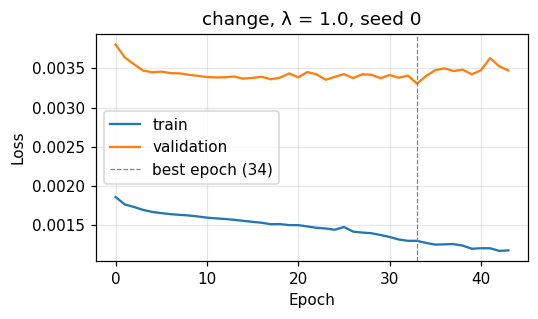

change λ=1.0  seed=0  epochs= 34  skill=-13.8 %  F1@80=0.187
Epoch 1/100
262/262 - 23s - 88ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 2/100
262/262 - 19s - 74ms/step - loss: 0.0017 - val_loss: 0.0036
Epoch 3/100
262/262 - 22s - 86ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 4/100
262/262 - 41s - 156ms/step - loss: 0.0017 - val_loss: 0.0036
Epoch 5/100
262/262 - 20s - 75ms/step - loss: 0.0017 - val_loss: 0.0037
Epoch 6/100
262/262 - 22s - 86ms/step - loss: 0.0017 - val_loss: 0.0036
Epoch 7/100
262/262 - 40s - 153ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 8/100
262/262 - 20s - 75ms/step - loss: 0.0016 - val_loss: 0.0035
Epoch 9/100
262/262 - 22s - 82ms/step - loss: 0.0016 - val_loss: 0.0035
Epoch 10/100
262/262 - 41s - 156ms/step - loss: 0.0016 - val_loss: 0.0035
Epoch 11/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0035
Epoch 12/100
262/262 - 21s - 80ms/step - loss: 0.0016 - val_loss: 0.0035
Epoch 13/100
262/262 - 20s - 76ms/step - loss: 0.0016 - val_loss: 0.0

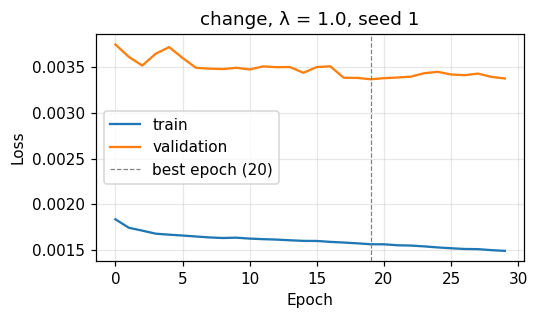

change λ=1.0  seed=1  epochs= 20  skill= -0.2 %  F1@80=0.142
Epoch 1/100
262/262 - 23s - 87ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 2/100
262/262 - 20s - 78ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 3/100
262/262 - 21s - 82ms/step - loss: 0.0017 - val_loss: 0.0036
Epoch 4/100
262/262 - 20s - 77ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 5/100
262/262 - 20s - 78ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 6/100
262/262 - 21s - 80ms/step - loss: 0.0017 - val_loss: 0.0034
Epoch 7/100
262/262 - 20s - 75ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 8/100
262/262 - 21s - 82ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 9/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 10/100
262/262 - 23s - 86ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 11/100
262/262 - 20s - 75ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 12/100
262/262 - 21s - 82ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 13/100
262/262 - 20s - 74ms/step - loss: 0.0016 - val_loss: 0.0034

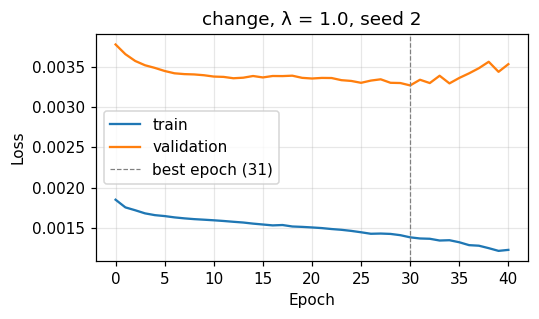

change λ=1.0  seed=2  epochs= 31  skill= -2.4 %  F1@80=0.176


In [9]:
SETUPS = [("level", 0.0), ("level", 1.0), ("change", 0.0), ("change", 1.0)]   # (target, λ)
INPUTS = ["G"]

results = pd.read_csv(RESULTS_FILE) if os.path.exists(RESULTS_FILE) else pd.DataFrame()

for target, lam in SETUPS:
    for seed in SEEDS:
        done = (not results.empty and
                ((results["target"] == target) & (results["lambda"] == lam) & (results["seed"] == seed)).any())
        if done:
            continue                                                  # already in the CSV file
        res = run_experiment(target, lam, INPUTS, seed)
        results = pd.concat([results, pd.DataFrame([res])], ignore_index=True)
        results.to_csv(RESULTS_FILE, index=False)                    # save after every run
        print(f"{target:6s} λ={lam:<4} seed={seed}  epochs={res['best epoch']:3d}  "
              f"skill={res['skill all']:5.1f} %  F1@{THRESHOLD}={res[f'F1 @{THRESHOLD}']:.3f}")

## 10. Results

The results are computed from the saved test forecasts, so all tables use exactly the same forecasts. The four LSTM versions are named **target / loss**:

| Name | The LSTM predicts | Trained with |
|---|---|---|
| value / MSE | the irradiance values | plain MSE (the standard LSTM) |
| value / ramp-aware | the irradiance values | MSE + ramp term |
| change / MSE | the change from the current value | plain MSE |
| change / ramp-aware | the change from the current value | MSE + ramp term |

Persistence (the current value repeated for all lead times) is included as the reference. With several seeds, every value is shown as **mean ± standard deviation over the seeds**; a difference between two models counts only if it is clearly larger than these ± values.

**Metrics.** MAE, RMSE, MAPE (only where irradiance > 50 W/m², to avoid dividing by values close to 0), R² and MASE. MASE divides the MAE of a model by the MAE of the naive forecast (persistence) on the training days, for the same lead time (Hyndman & Koehler, 2006): **MASE < 1 means better than the naive forecast**, MASE > 1 worse.

In [10]:
# =====================================================================
# A) Collect the test forecasts: persistence + every saved LSTM run
# =====================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

MAPE_MIN = 50                                         # W/m²: MAPE only where irradiance is above this
(_, Y_tr, now_tr, _), _, (_, Y_te, now_te, t_te) = get_windows(["G"]).values()
types_te = np.array([DAY_TYPE[d] for d in t_te.date])  # day type of every test forecast

def model_name(target, lam):
    return f"{'value' if target == 'level' else 'change'} / {'MSE' if lam == 0 else 'ramp-aware'}"

# One entry per (model, seed); persistence has no seed
runs = [("persistence", "-", np.repeat(now_te, HORIZON, axis=1))]
for target, lam in SETUPS:
    for seed in SEEDS:
        file = f"pred_{target}_lam{lam}_seed{seed}.npy"
        if os.path.exists(file):
            runs.append((model_name(target, lam), seed, np.load(file)))
MODELS = list(dict.fromkeys(name for name, _, _ in runs))          # model names in a fixed order
print(f"Forecasts found: {len(runs) - 1} LSTM runs + persistence")

# MASE scale (Hyndman & Koehler, 2006): MAE of the naive forecast (persistence) on the TRAINING days,
# for each lead time. Compare a model's MASE with the persistence row (lower = better).
mase_scale = np.abs(Y_tr - now_tr).mean(axis=0)       # one value per lead time

def metrics(y, p, scale):
    big = y > MAPE_MIN
    mse = mean_squared_error(y, p)
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mse),
            "MAPE (%)": 100 * mean_absolute_percentage_error(y[big], p[big]),
            "R²": r2_score(y, p), "MASE": mean_absolute_error(y, p) / scale}

def mean_std(df, by, cols, digits):
    # "mean ± std" over the seeds; only the mean when there is a single value (e.g. persistence)
    g = df.groupby(by, sort=False)[cols]
    rnd = (lambda x: x.round(digits)) if digits else (lambda x: x.round().astype("Int64"))   # counts as whole numbers
    mean, std = rnd(g.mean()), rnd(g.std())
    return mean.astype(str) + (" ± " + std.astype(str)).where(g.std().notna(), "")

Forecasts found: 12 LSTM runs + persistence


### A. Accuracy for every lead time
One table per metric: models as rows, lead times (10–60 s) as columns. Read along a row to see how a model gets worse with lead time, and down a column to compare the models at the same lead time.

In [11]:
# =====================================================================
# B) Accuracy for every lead time (both test days together)
# =====================================================================
rows = []
for name, seed, P in runs:
    for k, lead in enumerate(LEADS):
        rows.append({"model": name, "seed": seed, "lead (s)": lead,
                     **metrics(Y_te[:, k], P[:, k], mase_scale[k])})
by_lead = pd.DataFrame(rows)

# One table per metric: models as rows, lead times as columns, mean ± std over the seeds
for metric in ["MAE", "RMSE", "MAPE (%)", "R²", "MASE"]:
    print(f"\n{metric} per lead time (s)")
    table = mean_std(by_lead, ["model", "lead (s)"], [metric], 3 if metric in ["R²", "MASE"] else 1)[metric]
    display(table.unstack("lead (s)").reindex(MODELS))


MAE per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,7.4,12.0,15.6,18.2,20.7,22.8
value / MSE,11.0 ± 0.3,15.6 ± 1.3,19.7 ± 1.9,23.0 ± 0.9,26.2 ± 0.9,27.8 ± 1.3
value / ramp-aware,11.1 ± 0.6,16.0 ± 1.1,20.7 ± 0.4,23.0 ± 2.1,26.2 ± 1.7,28.8 ± 0.9
change / MSE,9.6 ± 0.5,15.2 ± 1.0,19.1 ± 1.0,22.3 ± 1.2,24.9 ± 1.2,27.0 ± 1.5
change / ramp-aware,10.9 ± 1.3,17.1 ± 1.2,20.4 ± 1.4,25.0 ± 1.3,25.1 ± 1.5,28.9 ± 1.3



RMSE per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,34.0,50.6,61.1,68.9,74.9,79.9
value / MSE,34.1 ± 0.2,50.0 ± 0.6,59.4 ± 1.1,66.0 ± 1.3,71.3 ± 2.0,75.5 ± 3.0
value / ramp-aware,37.3 ± 0.3,52.6 ± 2.2,63.4 ± 0.8,68.8 ± 2.9,74.7 ± 3.5,79.3 ± 2.1
change / MSE,34.6 ± 1.1,51.5 ± 2.3,61.8 ± 3.1,68.9 ± 3.6,74.6 ± 4.3,78.8 ± 4.6
change / ramp-aware,37.6 ± 3.6,55.4 ± 2.1,64.6 ± 5.6,75.4 ± 6.5,75.7 ± 5.0,82.7 ± 5.2



MAPE (%) per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,1.9,3.2,4.2,5.1,5.8,6.5
value / MSE,3.0 ± 0.2,4.4 ± 0.3,5.7 ± 0.5,6.8 ± 0.3,7.9 ± 0.3,8.6 ± 0.5
value / ramp-aware,3.4 ± 0.5,5.0 ± 0.6,6.7 ± 0.3,7.2 ± 1.1,8.5 ± 0.7,9.5 ± 0.3
change / MSE,2.8 ± 0.3,4.6 ± 0.6,6.0 ± 0.6,7.1 ± 0.6,8.0 ± 0.7,8.7 ± 0.8
change / ramp-aware,3.3 ± 0.7,5.4 ± 0.6,6.5 ± 0.7,8.2 ± 0.8,8.0 ± 0.7,9.6 ± 0.6



R² per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,0.984,0.964,0.947,0.933,0.92,0.91
value / MSE,0.984 ± 0.0,0.965 ± 0.001,0.95 ± 0.002,0.938 ± 0.002,0.928 ± 0.004,0.919 ± 0.006
value / ramp-aware,0.98 ± 0.0,0.961 ± 0.003,0.943 ± 0.002,0.933 ± 0.006,0.921 ± 0.007,0.911 ± 0.005
change / MSE,0.983 ± 0.001,0.962 ± 0.003,0.946 ± 0.005,0.933 ± 0.007,0.921 ± 0.009,0.912 ± 0.01
change / ramp-aware,0.98 ± 0.004,0.957 ± 0.003,0.941 ± 0.01,0.919 ± 0.014,0.919 ± 0.011,0.903 ± 0.012



MASE per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,1.627,1.679,1.73,1.712,1.716,1.716
value / MSE,2.401 ± 0.074,2.185 ± 0.186,2.186 ± 0.213,2.163 ± 0.082,2.17 ± 0.073,2.09 ± 0.098
value / ramp-aware,2.423 ± 0.123,2.24 ± 0.159,2.288 ± 0.046,2.156 ± 0.197,2.166 ± 0.144,2.166 ± 0.066
change / MSE,2.097 ± 0.112,2.12 ± 0.146,2.117 ± 0.111,2.094 ± 0.108,2.064 ± 0.099,2.034 ± 0.114
change / ramp-aware,2.379 ± 0.281,2.393 ± 0.171,2.262 ± 0.154,2.349 ± 0.124,2.077 ± 0.122,2.179 ± 0.096


**Results (3 seeds): accuracy per lead time**

- **Typical errors (MAE, MAPE): persistence is best at every lead time.** At 10 s its MAE is 7.4 W/m², against 9.6 ± 0.5 W/m² for the best LSTM; at 60 s 22.8 against 27.0 ± 1.5 W/m². The gaps are much larger than the variation between seeds.
- **Large errors (RMSE): only the standard LSTM (*value / MSE*) beats persistence, at 30–60 s.** At 10–20 s it is equal to persistence; at 60 s its RMSE is 75.5 ± 3.0 W/m² against 79.9 W/m² (about 5 % lower).
- **Value vs change target: a trade-off.** *change / MSE* has the lowest MAE of all LSTMs (clearly at 10 s: 9.6 ± 0.5 vs 11.0 ± 0.3 W/m²), but its RMSE is only equal to persistence, while *value / MSE* is better. The change setups also vary more between seeds. The one-seed result, in which the change target looked worse overall, is therefore not confirmed.
- **The ramp-aware loss costs accuracy.** *value / ramp-aware* is equal to persistence in RMSE at 40–60 s and worse at shorter lead times; *change / ramp-aware* is the least accurate setup and the least stable between seeds.
- **R² and MASE** confirm these rankings; R² is above 0.90 for all models, including persistence.

### B. Accuracy per test day
All lead times together, separately for the broken-cloud day (25 Feb) and the clear day (26 Feb). This shows where each model gains or loses against persistence.

In [12]:
# =====================================================================
# C) Accuracy per test day (all lead times together)
# =====================================================================
rows = []
for typ in ["broken clouds", "clear"]:
    m = types_te == typ
    for name, seed, P in runs:
        rows.append({"day": typ, "model": name, "seed": seed,
                     **metrics(Y_te[m].ravel(), P[m].ravel(), mase_scale.mean())})
by_day = pd.DataFrame(rows)
display(mean_std(by_day, ["day", "model"], ["MAE", "RMSE", "MAPE (%)", "R²"], 2))

MAE          RMSE      MAPE (%)  \
day           model                                                           
broken clouds persistence                 30.53         89.79           8.3   
              value / MSE           35.7 ± 1.11   85.96 ± 2.2  10.79 ± 0.47   
              value / ramp-aware   38.36 ± 1.84  90.81 ± 2.64  12.33 ± 0.82   
              change / MSE          36.0 ± 2.11  89.68 ± 4.73  11.32 ± 1.25   
              change / ramp-aware  39.12 ± 2.18  94.62 ± 6.57  12.61 ± 1.15   
clear         persistence                  1.75          2.25          0.57   
              value / MSE           5.42 ± 2.06   6.86 ± 2.58   1.33 ± 0.38   
              value / ramp-aware    3.53 ± 0.18   4.59 ± 0.13   1.05 ± 0.11   
              change / MSE          3.37 ± 0.17   4.35 ± 0.34   1.03 ± 0.12   
              change / ramp-aware   3.37 ± 0.55   4.32 ± 0.76   1.04 ± 0.17   

                                            R²  
day           model                             
broken clouds persistence                 0.87  
              value / MSE          0.88 ± 0.01  
              value / ramp-aware   0.87 ± 0.01  
              change / MSE         0.87 ± 0.01  
              change / ramp-aware  0.85 ± 0.02  
clear         persistence                  1.0  
              value / MSE            1.0 ± 0.0  
              value / ramp-aware     1.0 ± 0.0  
              change / MSE           1.0 ± 0.0  
              change / ramp-aware    1.0 ± 0.0

**Results (3 seeds): accuracy per test day**

- **Broken-cloud day.** Persistence has the lowest MAE (30.5 W/m²; LSTMs 35.7–39.1 W/m²). In RMSE, only *value / MSE* is clearly better than persistence (86.0 ± 2.2 vs 89.8 W/m², about 4 % lower); *change / MSE* and *value / ramp-aware* are about equal to persistence (89.7 ± 4.7 and 90.8 ± 2.6 W/m²), and *change / ramp-aware* is worse (94.6 ± 6.6 W/m²).
- **Clear day.** Persistence is almost exact (MAE 1.75 W/m²). The standard LSTM (*value / MSE*) has the largest and least stable error (MAE 5.4 ± 2.1 W/m²). Predicting the change or using the ramp-aware loss both reduce the clear-day error by about a third and make it stable between seeds (MAE 3.4–3.5 ± 0.2 W/m²), but no LSTM reaches persistence.
- **Why the ramp-aware loss helps on a calm day:** its second term compares the size of predicted and real changes. When the real changes are close to zero, it penalises small, unnecessary changes, which the standard LSTM adds on the clear day.

**Conclusion.** No setup is best on both days: the standard LSTM is the most accurate on the broken-cloud day but the worst and least stable on the clear day, while the change target and the ramp-aware loss improve the clear day at no clear gain on the cloudy day.

### C. Ramps on the broken-cloud test day: counts
For each model we count, along all forecast paths (10-s steps from now to +60 s):

- **real ramps:** measured 10-s steps larger than the threshold;
- **predicted ramps:** forecast 10-s steps larger than the threshold;
- **real ramps caught / missed:** real ramps with / without a predicted ramp in the same direction within ±10 s;
- **false alarms:** predicted ramps without a real ramp within ±10 s;
- **precision** = correct predicted ramps / predicted ramps; **recall** = caught / real ramps; **F1** combines both;
- **recall drops / recall rises:** recall separately for drops (sun becomes blocked) and rises (sun returns). If rises are caught much more often, the models mainly predict recoveries after a drop rather than the arrival of a cloud.

Persistence never predicts a change, so it predicts no ramps.

In [13]:
# =====================================================================
# D) Ramps on the broken-cloud test day: counts, and drops vs rises
# =====================================================================
def ramp_counts(obs, pred, thr):
    # Counts for down- and up-ramps (a ramp = 10-s step larger than thr along the forecast path)
    res = {"real ramps": 0, "predicted ramps": 0, "real ramps caught": 0, "correct": 0}
    for label, sign in [("drops", -1), ("rises", +1)]:
        o, p = sign * obs > thr, sign * pred > thr
        caught = (o & widen(p, TOL)).sum()                 # real ramps that were predicted (±10 s)
        res["real ramps"]        += o.sum()
        res["predicted ramps"]   += p.sum()
        res["real ramps caught"] += caught
        res["correct"]           += (p & widen(o, TOL)).sum()   # predicted ramps that really happened
        res[f"recall {label}"]    = caught / o.sum() if o.sum() else np.nan
    res["real ramps missed"] = res["real ramps"] - res["real ramps caught"]
    res["false alarms"]      = res["predicted ramps"] - res.pop("correct")
    n_pred, n_obs = res["predicted ramps"], res["real ramps"]
    res["precision"] = (n_pred - res["false alarms"]) / n_pred if n_pred else np.nan
    res["recall"]    = res["real ramps caught"] / n_obs
    p_, r_ = res["precision"], res["recall"]
    res["F1"] = 2 * p_ * r_ / (p_ + r_) if n_pred and (p_ + r_) else 0.0
    return res

m = types_te == "broken clouds"
obs_steps = np.diff(np.hstack([now_te, Y_te]), axis=1)[m]           # real 10-s steps along each path
rows = []
for thr in [THRESHOLD, THRESHOLD_CHECK]:
    for name, seed, P in runs:
        pred_steps = np.diff(np.hstack([now_te, P]), axis=1)[m]     # predicted 10-s steps
        rows.append({"threshold (W/m²)": thr, "model": name, "seed": seed,
                     **ramp_counts(obs_steps, pred_steps, thr)})
ramps = pd.DataFrame(rows)

COUNT_COLS = ["real ramps", "predicted ramps", "real ramps caught", "real ramps missed", "false alarms"]
RATE_COLS  = ["precision", "recall", "recall drops", "recall rises", "F1"]
display(pd.concat([mean_std(ramps, ["threshold (W/m²)", "model"], COUNT_COLS, 0),
                   mean_std(ramps, ["threshold (W/m²)", "model"], RATE_COLS, 3)], axis=1))

# How many separate ramps really happened on this day (each counted once, not once per forecast path)?
day = TEST_DAYS[[DAY_TYPE[d] for d in TEST_DAYS].index("broken clouds")]
real_once = (changes_of_day(day).abs() > THRESHOLD).sum()
print(f"Separate 10-s ramps on {day}: {real_once}. Each appears in up to {HORIZON} overlapping forecast paths, "
      f"which is why 'real ramps' in the table is about {HORIZON} times larger.")

real ramps predicted ramps  \
threshold (W/m²) model                                            
80               persistence               1500               0   
                 value / MSE           1500 ± 0         26 ± 30   
                 value / ramp-aware    1500 ± 0       627 ± 152   
                 change / MSE          1500 ± 0         94 ± 82   
                 change / ramp-aware   1500 ± 0       742 ± 166   
60               persistence               1830               0   
                 value / MSE           1830 ± 0       105 ± 106   
                 value / ramp-aware    1830 ± 0      1156 ± 197   
                 change / MSE          1830 ± 0       180 ± 157   
                 change / ramp-aware   1830 ± 0      1209 ± 172   

                                     real ramps caught real ramps missed  \
threshold (W/m²) model                                                     
80               persistence                         0              1500   
                 value / MSE                     5 ± 3          1495 ± 3   
                 value / ramp-aware           178 ± 44         1322 ± 44   
                 change / MSE                    9 ± 8          1491 ± 8   
                 change / ramp-aware          190 ± 35         1310 ± 35   
60               persistence                         0              1830   
                 value / MSE                   26 ± 15         1804 ± 15   
                 value / ramp-aware           391 ± 54         1439 ± 54   
                 change / MSE                  34 ± 30         1796 ± 30   
                 change / ramp-aware          378 ± 37         1452 ± 37   

                                     false alarms      precision  \
threshold (W/m²) model                                             
80               persistence                    0            nan   
                 value / MSE              22 ± 27  0.284 ± 0.196   
                 value / ramp-aware     463 ± 125   0.264 ± 0.04   
                 change / MSE             84 ± 74  0.112 ± 0.036   
                 change / ramp-aware    555 ± 149  0.259 ± 0.048   
60               persistence                    0            nan   
                 value / MSE              83 ± 93   0.285 ± 0.11   
                 value / ramp-aware     810 ± 151  0.301 ± 0.015   
                 change / MSE           147 ± 128  0.182 ± 0.018   
                 change / ramp-aware    847 ± 146  0.301 ± 0.031   

                                             recall   recall drops  \
threshold (W/m²) model                                               
80               persistence                    0.0            0.0   
                 value / MSE          0.004 ± 0.002    0.0 ± 0.001   
                 value / ramp-aware   0.119 ± 0.029  0.077 ± 0.028   
                 change / MSE         0.006 ± 0.005      0.0 ± 0.0   
                 change / ramp-aware  0.126 ± 0.023   0.095 ± 0.03   
60               persistence                    0.0            0.0   
                 value / MSE          0.014 ± 0.008  0.004 ± 0.005   
                 value / ramp-aware   0.214 ± 0.029  0.175 ± 0.037   
                 change / MSE         0.019 ± 0.017  0.004 ± 0.003   
                 change / ramp-aware   0.207 ± 0.02  0.186 ± 0.016   

                                       recall rises             F1  
threshold (W/m²) model                                              
80               persistence                    0.0            0.0  
                 value / MSE          0.007 ± 0.004  0.007 ± 0.004  
                 value / ramp-aware   0.163 ± 0.035  0.162 ± 0.027  
                 change / MSE         0.012 ± 0.011   0.011 ± 0.01  
                 change / ramp-aware  0.161 ± 0.016  0.168 ± 0.023  
60               persistence                    0.0            0.0  
                 value / MSE          0.025 ± 0.011  0.026 ± 0.013  
                 value / ramp-aware   0.

Separate 10-s ramps on 2013-02-25: 250. Each appears in up to 6 overlapping forecast paths, which is why 'real ramps' in the table is about 6 times larger.


**Results (3 seeds): ramps on the broken-cloud test day**

On 25 Feb there were 250 separate ramps (10-s changes > 80 W/m²), i.e. 1500 ramp steps along the forecast paths.

- **Both MSE-trained LSTMs are blind to ramps**, whatever the target: they caught 5 ± 3 (*value*) and 9 ± 8 (*change*) of the 1500 ramp steps (recall below 1 %), and no drops at all.
- **The ramp-aware loss makes the LSTM detect ramps.** With the value target it caught 178 ± 44 ramp steps (recall 11.9 %, F1 0.16), about 35 times more than with MSE. About three of every four predicted ramps were false alarms (precision 0.26). The ranking is the same at 60 W/m² (F1 0.026 → 0.25).
- **The models mainly predict recoveries.** With the ramp-aware loss, rises were caught about twice as often as drops (value target: 16.3 % vs 7.7 %). From past irradiance alone, the models learn that the sun returns soon after a drop, but can hardly foresee the arrival of a cloud, in line with the data exploration.
- **The target does not change ramp detection:** with the ramp-aware loss, the value and change targets caught the same number of ramps (178 ± 44 vs 190 ± 35) with the same precision.

## Conclusion of E1

1. **Ramp-aware loss (question 1).** It turns a ramp-blind LSTM into one that catches about 12 % of the ramp steps (35 times more), at the cost of many false alarms and a loss of accuracy: on the broken-cloud day its RMSE is about equal to persistence instead of 4 % better. On the clear day it also reduces the error of the standard LSTM by about a third, because it penalises unnecessary changes.
2. **Change vs value target (question 2).** Predicting the change gives a lower MAE at short lead times and a lower clear-day error, but no gain on the broken-cloud day, no gain in ramp detection, and less stable results between seeds. **The value target is kept for the next experiments.**
3. **Limits of univariate forecasting.** With past irradiance as the only input, all models react to clouds rather than foresee them: they mainly predict recoveries after a drop, and most ramps are missed.

### D. What the forecasts look like
Measured irradiance and the forecasts of all models (first seed) for 20 minutes on the broken-cloud test day, at one lead time (change `LEAD_SHOW` to see another one). A good ramp forecast drops and rises with the measured curve; a smooth forecast stays in the middle.

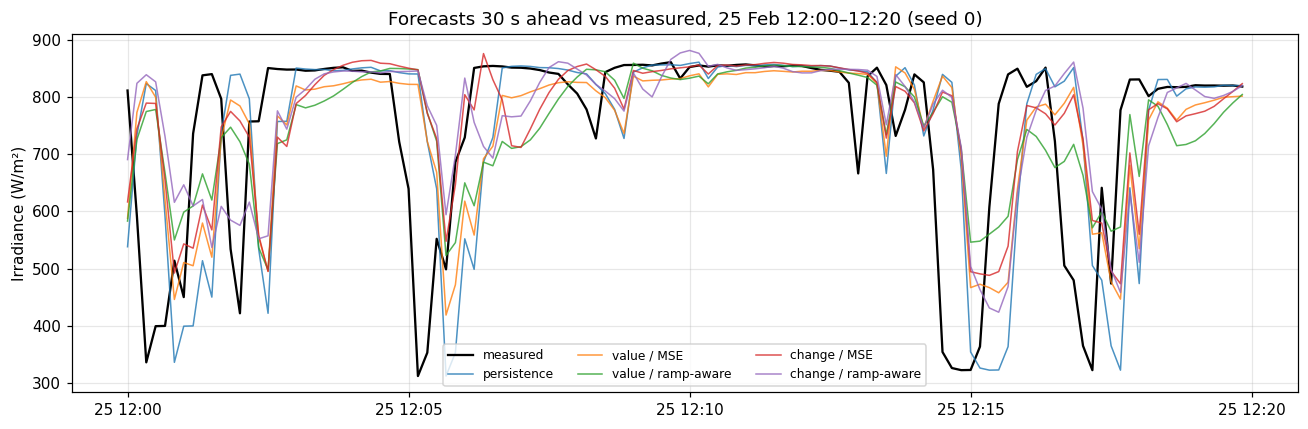

In [14]:
# =====================================================================
# E) What the forecasts look like: 20 minutes on the broken-cloud test day (first seed)
# =====================================================================
LEAD_SHOW = 30                                         # lead time to show (s): 10, 20, ..., 60
k = list(LEADS).index(LEAD_SHOW)
t_target = t_te + pd.Timedelta(seconds=LEAD_SHOW)      # the time each forecast is for
show = (t_target >= "2013-02-25 12:00") & (t_target < "2013-02-25 12:20")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_target[show], Y_te[show, k], color="k", lw=1.5, label="measured")
for name, seed, P in runs:
    if seed in ("-", SEEDS[0]):                        # persistence + the first seed of each LSTM
        ax.plot(t_target[show], P[show, k], lw=1, alpha=0.8, label=name)
ax.set_ylabel("Irradiance (W/m²)")
ax.set_title(f"Forecasts {LEAD_SHOW} s ahead vs measured, 25 Feb 12:00–12:20 (seed {SEEDS[0]})")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

## Overall conclusion of E1 / E1b

### What we did
We trained a simple univariate LSTM (one layer of 64 units, input: the last 10 minutes of 10-s irradiance, output: the next 6 values, 10–60 s ahead) in four setups: two **targets** (predicting the irradiance values, or the change from the current value) × two **losses** (plain MSE, or MSE plus a term on the size of the 10-s changes, λ = 1). Each setup was trained with 3 random seeds. The models were tested on a broken-cloud day (25 Feb) and a clear day (26 Feb), against persistence, with standard error metrics (MAE, RMSE, MAPE, R², MASE) per lead time and per day, and with ramp counts (ramp = 10-s change > 80 W/m²) on the broken-cloud day.

### Why
Forecasting models are usually trained with MSE and judged by RMSE. MSE rewards smooth forecasts, so a model can look good on RMSE while missing the sudden changes (ramps) that matter for grid and battery control. E1 tests (1) whether a ramp-aware loss makes the model detect ramps and at what cost, and (2) whether predicting the change instead of the value helps, especially on clear days, where persistence is almost exact.

### What we found
1. **The MSE-trained LSTM is blind to ramps.** It caught 5 ± 3 of the 1500 ramp steps (recall below 1 %) and no drops at all.
2. **The ramp-aware loss makes it detect ramps:** 178 ± 44 ramp steps caught (recall 12 %), about 35 times more, with many false alarms (precision 0.26). The result is the same at 60 W/m².
3. **This costs accuracy.** On the broken-cloud day, the MSE model is about 4 % better than persistence in RMSE (86.0 ± 2.2 vs 89.8 W/m²), while the ramp-aware model is about equal to persistence. On the clear day, the ramp-aware loss *reduces* the error of the standard LSTM by about a third, because it also penalises unnecessary changes when the sky is calm.
4. **Persistence has the lowest MAE at every lead time and on both days.** The LSTMs beat persistence only in RMSE, only on the broken-cloud day and only at 30–60 s, i.e. by avoiding the largest errors during ramps (hedging), not by being closer most of the time.
5. **Predicting the change is a trade-off, not an improvement:** lower MAE at short lead times and on the clear day, but no gain on the broken-cloud day, no gain in ramp detection and less stable results between seeds. The value target is kept.
6. **The models react rather than foresee.** Rises (the sun returning) were caught about twice as often as drops (a cloud arriving). From past irradiance alone, the models learn that shadows are short, but can hardly see a cloud coming.

### Limitations
- **The LSTM is a simple, untuned baseline.** Its comparison with persistence should be read as "this baseline LSTM vs persistence", not as a general statement about LSTMs. The comparison between the two losses is fair, since both use the same model, but it should be confirmed with a stronger (tuned or deeper) model.
- **Univariate input:** the models see only past irradiance from the same site, which cannot show approaching clouds.
- **One broken-cloud test day and 3 seeds;** the robustness experiment (each broken-cloud day as test day) is still to come.
- **λ = 1 was not tuned;** a smaller λ may keep more accuracy while still detecting ramps (tested in E2).

### Next
E2: λ sweep (0, 0.1, 0.3, 1, 3) with the value target, to find the best balance between accuracy and ramp detection. Later: input groups (clear-sky index, recent variability, time of day), a stronger tuned model, and robustness across test days.